# Advanced Statistical Analysis & Hypothesis Testing
## Clinical Cohort Study: Inpatient Glycemic Monitoring and Hospital Stay Duration
**Author**: Senior Statistician & Research Data Scientist  
**Dataset**: Diabetes 130-US Hospitals (1999–2008)  
**Target Outcome**: Hospital Length of Stay (`time_in_hospital`, Integer Days)  
**Primary Predictors**: Glycated Hemoglobin Testing (`A1Cresult`) & Admission Urgency (`admission_type_id`)

---

### 1. Project Introduction & Research Context
Inpatient management of diabetes mellitus represents a major determinant of acute healthcare utilization and clinical outcomes. Clinical guidelines from the American Diabetes Association (ADA) strongly recommend obtaining an **inpatient glycated hemoglobin (HbA1c)** test for all diabetic patients admitted to acute care if no test was performed within the preceding 90 days. Testing provides a 90-day window into chronic glycemic control, informing inpatient insulin titration, medication regimen modifications, and post-discharge coordination.

However, the empirical association between inpatient testing and acute healthcare utilization remains nuanced:
1. **Clinical Complexity & Acuity**: Patients who undergo testing often present with acute metabolic dysregulation or complex comorbidities that necessitate extended monitoring.
2. **Clinical Decision Latency**: Waiting for laboratory results, endocrinology consultations, and therapeutic stabilization can prolong acute hospitalization.
3. **Distributional Realities**: Hospital stay duration (`time_in_hospital`) is bounded below ($y \ge 1$), right-skewed, and discrete, violating classical Gaussian assumptions.

#### Analytical Objectives
This project executes a rigorous statistical analysis protocol:
- **Task 1: Normality Testing**: Formal evaluation using Shapiro-Wilk and Kolmogorov-Smirnov tests, combined with empirical moment estimation and graphical diagnostics (histograms, KDE, Q-Q plots).
- **Task 2: Two-Sample Hypothesis Testing**: Parametric (Welch's independent $t$-test) versus non-parametric (Mann-Whitney $U$ test) evaluation of hospital stay between tested and non-tested cohorts, complete with effect sizes and methodological synthesis.
- **Task 3: Analysis of Variance (ANOVA)**: One-Way ANOVA across HbA1c test result strata (`Norm`, `>7`, `>8`), Two-Way Factorial ANOVA evaluating main and interaction effects with admission urgency, and Tukey HSD post-hoc pairwise comparisons with Family-Wise Error Rate (FWER) control.
- **Task 4: Assumption Verification & Diagnostics**: Residual normality, homoscedasticity (Levene / Brown-Forsythe tests), and big-data sensitivity considerations.

---
### 2. Dataset Loading & Environment Setup
We load the Diabetes 130-US Hospitals dataset, along with ID mappings for hospital admission types.

In [1]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure src modules can be imported
sys.path.insert(0, os.path.abspath('..'))

from src.normality_tests import (
    compute_distribution_summary,
    shapiro_wilk_test,
    repeated_shapiro_wilk,
    kolmogorov_smirnov_test,
    run_comprehensive_normality_suite
)
from src.hypothesis_testing import (
    check_variance_homogeneity,
    welch_t_test,
    mann_whitney_u_test,
    compare_parametric_vs_nonparametric
)
from src.anova_analysis import (
    one_way_anova,
    two_way_anova,
    tukey_hsd_post_hoc
)
from src.visualization import (
    plot_distribution_overview,
    plot_normality_diagnostics,
    plot_hypothesis_comparison,
    plot_anova_distributions,
    plot_two_way_anova_interaction,
    plot_tukey_hsd_results,
    plot_anova_diagnostics
)

# Plot styling configuration
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8
sns.set_theme(style='whitegrid', palette='deep')

# Data file paths
data_path = os.path.join('..', 'data', 'diabetic_data.csv')
ids_path = os.path.join('..', 'data', 'IDS_mapping.csv')

raw_df = pd.read_csv(data_path)
print(f"Loaded Raw Dataset: {raw_df.shape[0]:,} rows, {raw_df.shape[1]} columns")
print("\nFirst 5 Records:")
print(raw_df[['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'admission_type_id', 'time_in_hospital', 'A1Cresult', 'readmitted']].head(5).to_string())

Loaded Raw Dataset: 101,766 rows, 50 columns

First 5 Records:
   encounter_id  patient_nbr             race  gender      age  admission_type_id  time_in_hospital A1Cresult readmitted
0       2278392      8222157        Caucasian  Female   [0-10)                  6                 1       NaN         NO
1        149190     55629189        Caucasian  Female  [10-20)                  1                 3       NaN        >30
2         64410     86047875  AfricanAmerican  Female  [20-30)                  1                 2       NaN         NO
3        500364     82442376        Caucasian    Male  [30-40)                  1                 2       NaN         NO
4         16680     42519267        Caucasian    Male  [40-50)                  1                 1       NaN         NO


---
### 3. Data Validation
Before initiating statistical modeling, we verify actual column names, data types, missing value patterns, and categorical distributions across the target variables:
- `A1Cresult`
- `time_in_hospital`
- `admission_type_id`
- `readmitted`
- `age`
- `gender`
- `num_lab_procedures`

In [2]:
target_variables = [
    'A1Cresult', 'time_in_hospital', 'admission_type_id',
    'readmitted', 'age', 'gender', 'num_lab_procedures'
]

validation_summary = []
for var in target_variables:
    col = raw_df[var]
    missing_cnt = col.isna().sum() + (col == '?').sum()
    validation_summary.append({
        'Variable': var,
        'Present': var in raw_df.columns,
        'Dtype': str(col.dtype),
        'Total_Obs': len(col),
        'Missing_or_Null': int(missing_cnt),
        'Pct_Missing': f"{(missing_cnt / len(col)) * 100:.2f}%",
        'Unique_Count': int(col.nunique(dropna=False))
    })

val_df = pd.DataFrame(validation_summary)
print("Variable Validation Profile:")
print(val_df.to_string(index=False))

print("\nA1Cresult raw frequency:")
print(raw_df['A1Cresult'].value_counts(dropna=False).to_string())
print("\nGender raw frequency:")
print(raw_df['gender'].value_counts(dropna=False).to_string())
print("\nAdmission Type ID raw frequency:")
print(raw_df['admission_type_id'].value_counts().head(8).to_string())

Variable Validation Profile:
          Variable  Present  Dtype  Total_Obs  Missing_or_Null Pct_Missing  Unique_Count
         A1Cresult     True object     101766            84748      83.28%             4
  time_in_hospital     True  int64     101766                0       0.00%            14
 admission_type_id     True  int64     101766                0       0.00%             8
        readmitted     True object     101766                0       0.00%             3
               age     True object     101766                0       0.00%            10
            gender     True object     101766                0       0.00%             3
num_lab_procedures     True  int64     101766                0       0.00%           118

A1Cresult raw frequency:
A1Cresult
NaN     84748
>8       8216
Norm     4990
>7       3812

Gender raw frequency:
gender
Female             54708
Male               47055
Unknown/Invalid        3

Admission Type ID raw frequency:
admission_type_id
1    53990

---
### 4. Data Cleaning & Cohort Construction
Data cleaning rules:
1. **Gender Validation**: 3 records have `Unknown/Invalid` gender; these are excluded to maintain clean clinical categorization.
2. **HbA1c Testing Status**:
   - `Tested`: `A1Cresult` $\in$ {`Norm`, `>7`, `>8`} ($N = 17,018$)
   - `Not Tested`: `A1Cresult` is NaN / `'None'` ($N = 84,745$)
3. **Admission Type Mapping**:
   Map integer IDs using `IDS_mapping.csv` to clinically distinct categories:
   - 1 = `Emergency` ($N = 53,988$)
   - 2 = `Urgent` ($N = 18,480$)
   - 3 = `Elective` ($N = 18,868$)
   - Values 4, 5, 6, 7, 8 represent newborn, trauma, unmapped, or missing administrative codes.

In [3]:
# 1. Gender filtering
clean_df = raw_df[raw_df['gender'] != 'Unknown/Invalid'].copy()
print(f"Cohort size after excluding invalid gender: {len(clean_df):,} records")

# 2. Binary testing indicator and categorical representation
clean_df['a1c_tested'] = np.where(clean_df['A1Cresult'].isin(['Norm', '>7', '>8']), 'Tested', 'Not Tested')
clean_df['a1c_category'] = clean_df['A1Cresult'].fillna('None')

# 3. Admission type mapping
adm_map = {1: 'Emergency', 2: 'Urgent', 3: 'Elective'}
clean_df['admission_type'] = clean_df['admission_type_id'].map(adm_map)

# 4. Enforce integer type on outcome
clean_df['time_in_hospital'] = clean_df['time_in_hospital'].astype(int)

print("\nClean Cohort Summary by Testing Status:")
print(clean_df['a1c_tested'].value_counts().to_string())
print("\nClean Cohort Summary by Clinical Admission Type:")
print(clean_df['admission_type'].value_counts(dropna=False).to_string())

Cohort size after excluding invalid gender: 101,763 records

Clean Cohort Summary by Testing Status:
a1c_tested
Not Tested    84745
Tested        17018

Clean Cohort Summary by Clinical Admission Type:
admission_type
Emergency    53988
Elective     18868
Urgent       18480
NaN          10427


---
### 5. Exploratory Distribution Analysis
We examine the distribution moments of the primary dependent variable: `time_in_hospital` (length of acute stay in days).

Summary Moments for time_in_hospital:
                   Metric               Value
          Sample Size (N)             101,763
              Mean (Days)              4.3960
       Standard Deviation              2.9851
            Median (Days)                 4.0
Interquartile Range (IQR)     4.0 (2.0 - 6.0)
        Range (Min - Max)              1 - 14
        Skewness (Fisher) 1.1340 (SE: 0.0077)
          Excess Kurtosis 0.8503 (SE: 0.0154)


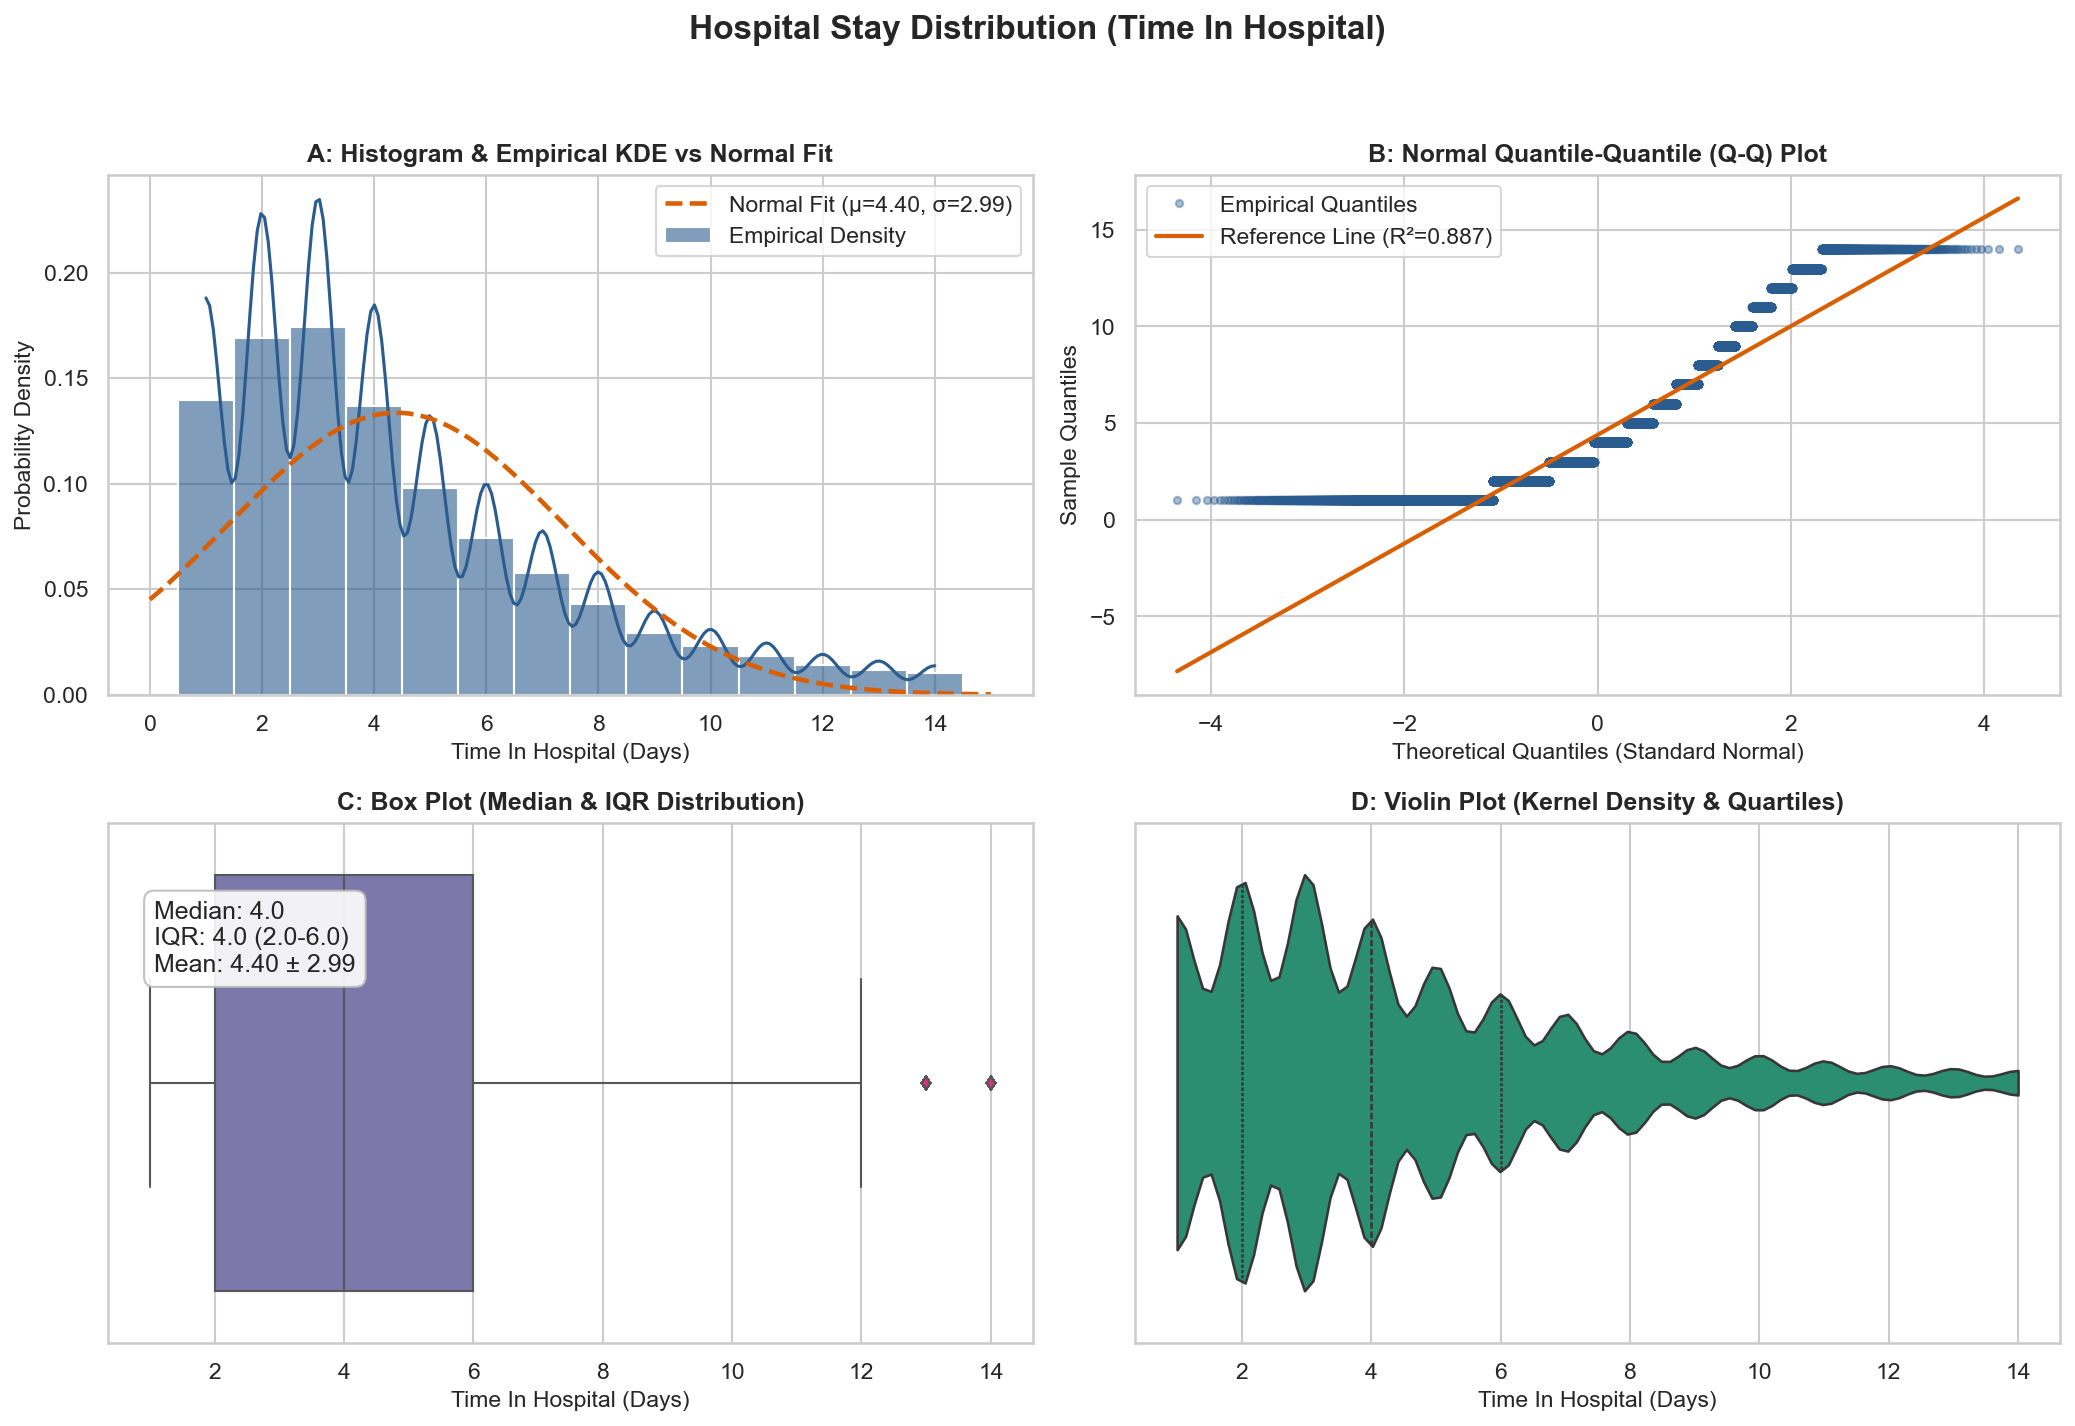

In [4]:
hosp_stay = clean_df['time_in_hospital'].values
dist_summary = compute_distribution_summary(hosp_stay, variable_name='time_in_hospital')

summary_table = pd.DataFrame([{
    'Metric': 'Sample Size (N)', 'Value': f"{dist_summary['n']:,}"
}, {
    'Metric': 'Mean (Days)', 'Value': f"{dist_summary['mean']:.4f}"
}, {
    'Metric': 'Standard Deviation', 'Value': f"{dist_summary['std']:.4f}"
}, {
    'Metric': 'Median (Days)', 'Value': f"{dist_summary['median']:.1f}"
}, {
    'Metric': 'Interquartile Range (IQR)', 'Value': f"{dist_summary['iqr']:.1f} ({dist_summary['q25']:.1f} - {dist_summary['q75']:.1f})"
}, {
    'Metric': 'Range (Min - Max)', 'Value': f"{dist_summary['min']:.0f} - {dist_summary['max']:.0f}"
}, {
    'Metric': 'Skewness (Fisher)', 'Value': f"{dist_summary['skewness']:.4f} (SE: {dist_summary['se_skewness']:.4f})"
}, {
    'Metric': 'Excess Kurtosis', 'Value': f"{dist_summary['excess_kurtosis']:.4f} (SE: {dist_summary['se_kurtosis']:.4f})"
}])

print("Summary Moments for time_in_hospital:")
print(summary_table.to_string(index=False))

# Multi-panel distribution plot
fig1 = plot_distribution_overview(hosp_stay, variable_name='time_in_hospital')
plt.show()

---
### 6. Normality Testing (Task 1)
We implement formal normality testing:
1. **Shapiro-Wilk Test**: Optimal for general normality, with algorithmic sample size considerations handled via representative sampling ($N=5,000$) and repeated Monte Carlo subsampling (50 draws $\times$ 2,000 observations).
2. **Kolmogorov-Smirnov Test**: Tests empirical cumulative distribution against a continuous fitted Gaussian distribution across all $N = 101,763$ observations.

#### Hypotheses:
- $H_0$: The population distribution of hospital stay duration follows a normal distribution.
- $H_1$: The population distribution of hospital stay duration does not follow a normal distribution.
- $\alpha = 0.05$

Normality Testing Suite Summary:
                                 Test Name Sample Size Evaluated           Test Statistic             p-value  Alpha  Reject H0?                          Conclusion
                         Shapiro-Wilk Test       5,000 (Sampled)               W = 0.8910          1.1354e-50   0.05        True               Non-Normal (Rejected)
         Repeated Subsampling Shapiro-Wilk 50 iterations x 2,000 Mean W = 0.8884 ± 0.0050 Mean p = 2.1588e-35   0.05        True 100% Rejection Rate across 50 draws
Kolmogorov-Smirnov Test (vs Fitted Normal) 101,763 (Full Cohort)               D = 0.1729          0.0000e+00   0.05        True               Non-Normal (Rejected)


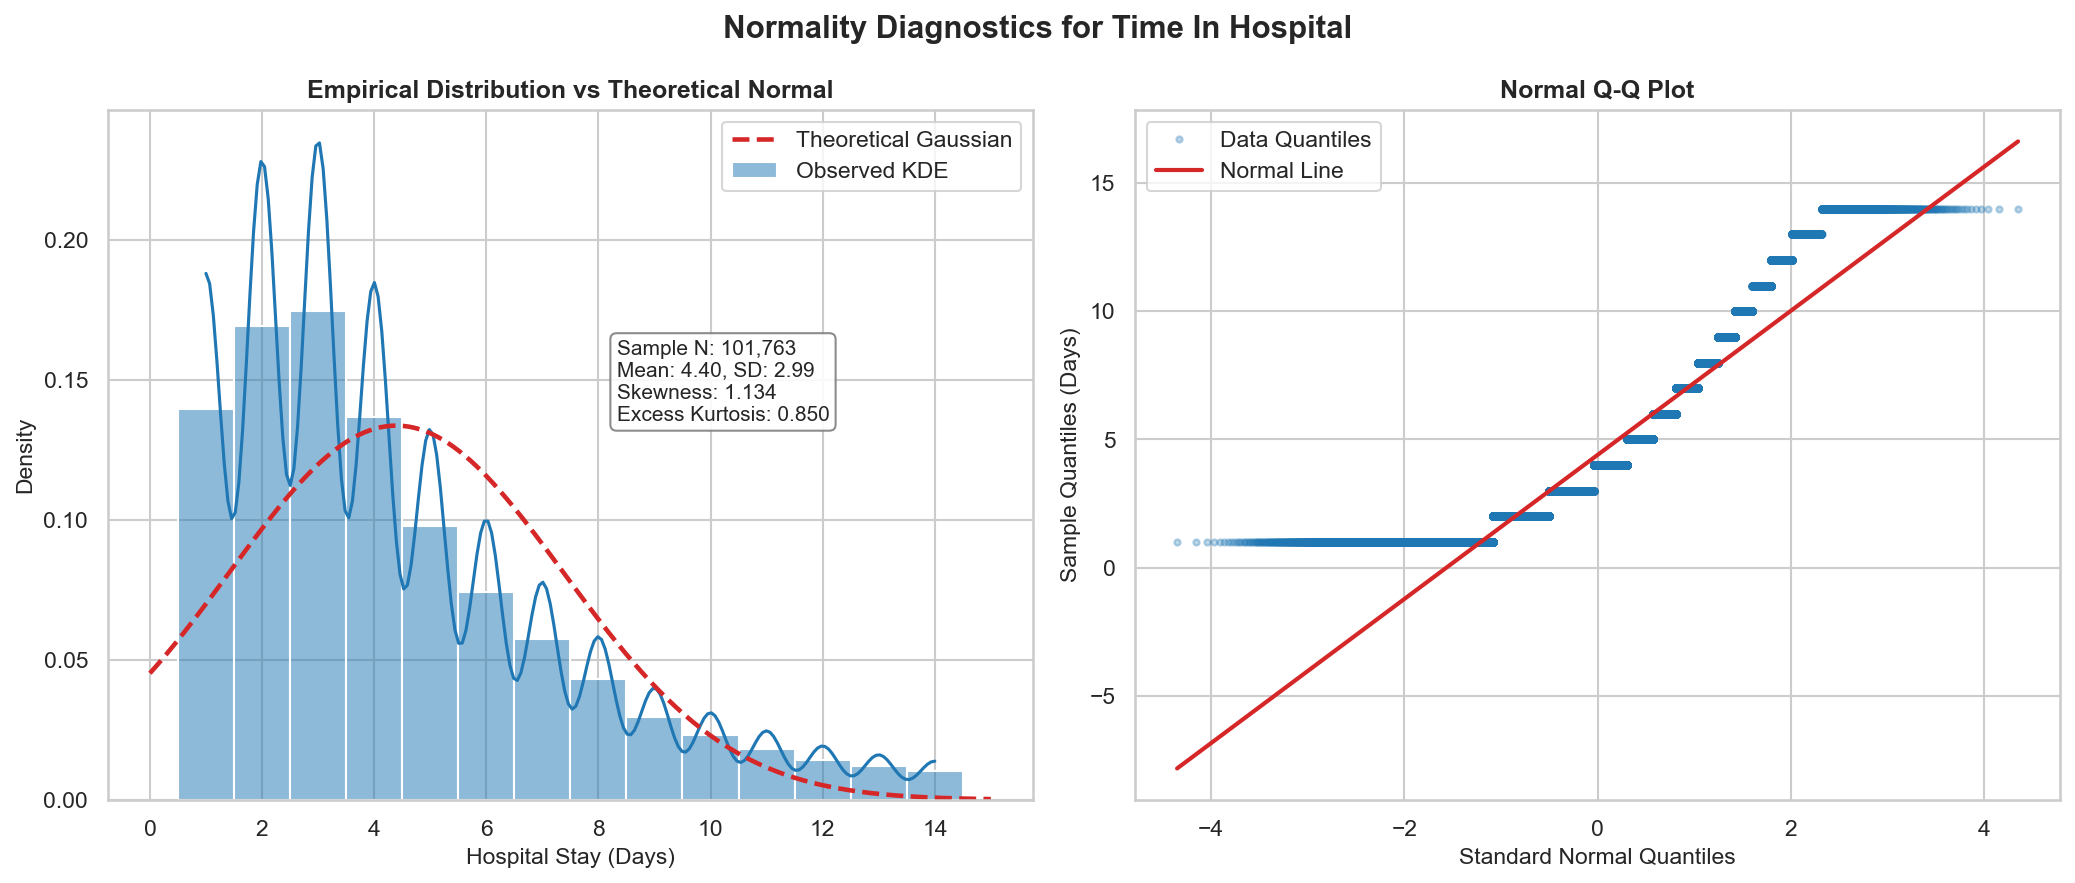

In [5]:
norm_results = run_comprehensive_normality_suite(hosp_stay, variable_name='time_in_hospital', alpha=0.05)

sw = norm_results['shapiro_wilk']
rep_sw = norm_results['repeated_shapiro_wilk']
ks = norm_results['kolmogorov_smirnov']

norm_table = pd.DataFrame([
    {
        'Test Name': sw['test_name'],
        'Sample Size Evaluated': f"{sw['effective_n']:,} (Sampled)",
        'Test Statistic': f"W = {sw['statistic']:.4f}",
        'p-value': f"{sw['p_value']:.4e}",
        'Alpha': sw['alpha'],
        'Reject H0?': sw['reject_null'],
        'Conclusion': 'Non-Normal (Rejected)'
    },
    {
        'Test Name': rep_sw['test_name'],
        'Sample Size Evaluated': f"50 iterations x {rep_sw['sample_size_per_iter']:,}",
        'Test Statistic': f"Mean W = {rep_sw['mean_statistic']:.4f} ± {rep_sw['std_statistic']:.4f}",
        'p-value': f"Mean p = {rep_sw['mean_p_value']:.4e}",
        'Alpha': rep_sw['alpha'],
        'Reject H0?': rep_sw['rejection_rate'] == 1.0,
        'Conclusion': f"100% Rejection Rate across {rep_sw['iterations']} draws"
    },
    {
        'Test Name': ks['test_name'],
        'Sample Size Evaluated': f"{ks['total_n']:,} (Full Cohort)",
        'Test Statistic': f"D = {ks['statistic']:.4f}",
        'p-value': f"{ks['p_value']:.4e}",
        'Alpha': ks['alpha'],
        'Reject H0?': ks['reject_null'],
        'Conclusion': 'Non-Normal (Rejected)'
    }
])

print("Normality Testing Suite Summary:")
print(norm_table.to_string(index=False))

# Diagnostic plot
fig2 = plot_normality_diagnostics(hosp_stay, variable_name='time_in_hospital')
plt.show()

#### Methodological Discussion: Statistical Significance vs Practical Importance
Normality tests exhibit **extreme statistical power** when applied to large healthcare datasets ($N > 100,000$). At this sample scale:
- Any microscopic departure from an idealized Gaussian curve (such as discrete positive integer rounding: 1, 2, 3... days) produces an astronomically small $p$-value ($p < 10^{-50}$).
- However, from a practical and modeling standpoint:
  - Skewness is moderate (+1.13), and excess kurtosis is modest (+0.85).
  - By the **Central Limit Theorem (CLT)**, the sampling distribution of the sample mean ($ar{X}$) approaches normality with standard error $\sigma / \sqrt{N} pprox 2.98 / \sqrt{101763} pprox 0.0093$ days.
  - Linear models and Welch's $t$-test are exceptionally robust to moderate skewness at $N > 1,000$. Nonetheless, coupling parametric tests with non-parametric alternatives (Mann-Whitney $U$) provides essential verification against distributional artifacts.

---
### 7. Independent Two-Sample t-Test (Task 2A)
We evaluate whether patients who received inpatient HbA1c testing differ in mean hospital stay compared to those who did not receive testing.

#### Hypotheses:
- $H_0: \mu_{\text{tested}} - \mu_{\text{not\_tested}} = 0$ (Equal population mean hospital stay)
- $H_1: \mu_{\text{tested}} - \mu_{\text{not\_tested}} \neq 0$ (Different population mean hospital stay)
- $\alpha = 0.05$

In [6]:
g_tested = clean_df.loc[clean_df['a1c_tested'] == 'Tested', 'time_in_hospital'].values
g_not_tested = clean_df.loc[clean_df['a1c_tested'] == 'Not Tested', 'time_in_hospital'].values

# Check variance homogeneity via Levene's test (Brown-Forsythe median centering)
levene_res = check_variance_homogeneity(g_tested, g_not_tested, center='median')
print(f"Levene's Test for Equal Variances:")
print(f"  Statistic: {levene_res['statistic']:.4f}, p-value: {levene_res['p_value']:.4e}")
print(f"  Equal Variance Justified? {levene_res['equal_variance_justified']}")
print(f"  Methodological Directive: {levene_res['recommended_t_test']}")

# Perform Welch's t-test
welch_res = welch_t_test(g_tested, g_not_tested, group1_name='Tested', group2_name='Not Tested')

ttest_summary = pd.DataFrame([{
    'Parameter': 'Tested Mean ± SD (n)', 'Value': f"{welch_res['mean1']:.4f} ± {welch_res['std1']:.4f} (n={welch_res['n1']:,})"
}, {
    'Parameter': 'Not Tested Mean ± SD (n)', 'Value': f"{welch_res['mean2']:.4f} ± {welch_res['std2']:.4f} (n={welch_res['n2']:,})"
}, {
    'Parameter': 'Mean Difference (Tested - Not Tested)', 'Value': f"+{welch_res['mean_diff']:.4f} days (SE: {welch_res['se_diff']:.4f})"
}, {
    'Parameter': 'Welch-Satterthwaite Degrees of Freedom', 'Value': f"{welch_res['df']:.1f}"
}, {
    'Parameter': 't-Statistic', 'Value': f"t = {welch_res['statistic']:.4f}"
}, {
    'Parameter': 'p-value (Two-Sided)', 'Value': f"{welch_res['p_value']:.4e}"
}, {
    'Parameter': '95% Confidence Interval', 'Value': f"[{welch_res['ci_lower']:.4f}, {welch_res['ci_upper']:.4f}] days"
}, {
    'Parameter': "Cohen's d (Pooled)", 'Value': f"{welch_res['cohens_d_pooled']:.4f} (Small Effect)"
}, {
    'Parameter': "Hedges' g (Bias Corrected)", 'Value': f"{welch_res['hedges_g']:.4f}"
}, {
    'Parameter': 'Statistical Decision at alpha=0.05', 'Value': 'Reject H0 (Statistically Significant)'
}])

print("\nWelch's Two-Sample t-Test Results:")
print(ttest_summary.to_string(index=False))

Levene's Test for Equal Variances:
  Statistic: 79.7382, p-value: 4.3435e-19
  Equal Variance Justified? False
  Methodological Directive: Welch's t-test (equal_var=False)

Welch's Two-Sample t-Test Results:
                             Parameter                                 Value
                  Tested Mean ± SD (n)            4.8319 ± 3.1128 (n=17,018)
              Not Tested Mean ± SD (n)            4.3085 ± 2.9510 (n=84,745)
 Mean Difference (Tested - Not Tested)             +0.5234 days (SE: 0.0259)
Welch-Satterthwaite Degrees of Freedom                               23559.7
                           t-Statistic                           t = 20.1882
                   p-value (Two-Sided)                            7.1631e-90
               95% Confidence Interval                 [0.4726, 0.5742] days
                    Cohen's d (Pooled)                 0.1757 (Small Effect)
            Hedges' g (Bias Corrected)                                0.1757
    Statistical Decisi

---
### 8. Mann-Whitney U Test (Task 2B)
Because `time_in_hospital` is discrete and right-skewed, we perform the non-parametric Mann-Whitney $U$ test (Wilcoxon rank-sum test) to assess stochastic dominance.

#### Hypotheses:
- $H_0: P(X_{\text{tested}} > Y_{\text{not\_tested}}) = P(Y_{\text{not\_tested}} > X_{\text{tested}})$ (Stochastically equivalent distributions)
- $H_1: P(X_{\text{tested}} > Y_{\text{not\_tested}}) \neq P(Y_{\text{not\_tested}} > X_{\text{tested}})$ (Stochastic dominance)
- $\alpha = 0.05$

Mann-Whitney U Test Results:
                         Parameter                                 Value
               Tested Median (IQR)               4.0 (IQR 5.0, n=17,018)
           Not Tested Median (IQR)               4.0 (IQR 4.0, n=84,745)
          Mann-Whitney U Statistic                     U = 796,990,222.0
                Asymptotic Z-Score                           Z = 21.8899
               p-value (Two-Sided)                           3.2452e-106
  Rank-Biserial Correlation (r_rb)                               -0.1052
Rank Effect Size (r = Z / sqrt(N))                 0.0686 (Small Effect)
Statistical Decision at alpha=0.05 Reject H0 (Statistically Significant)


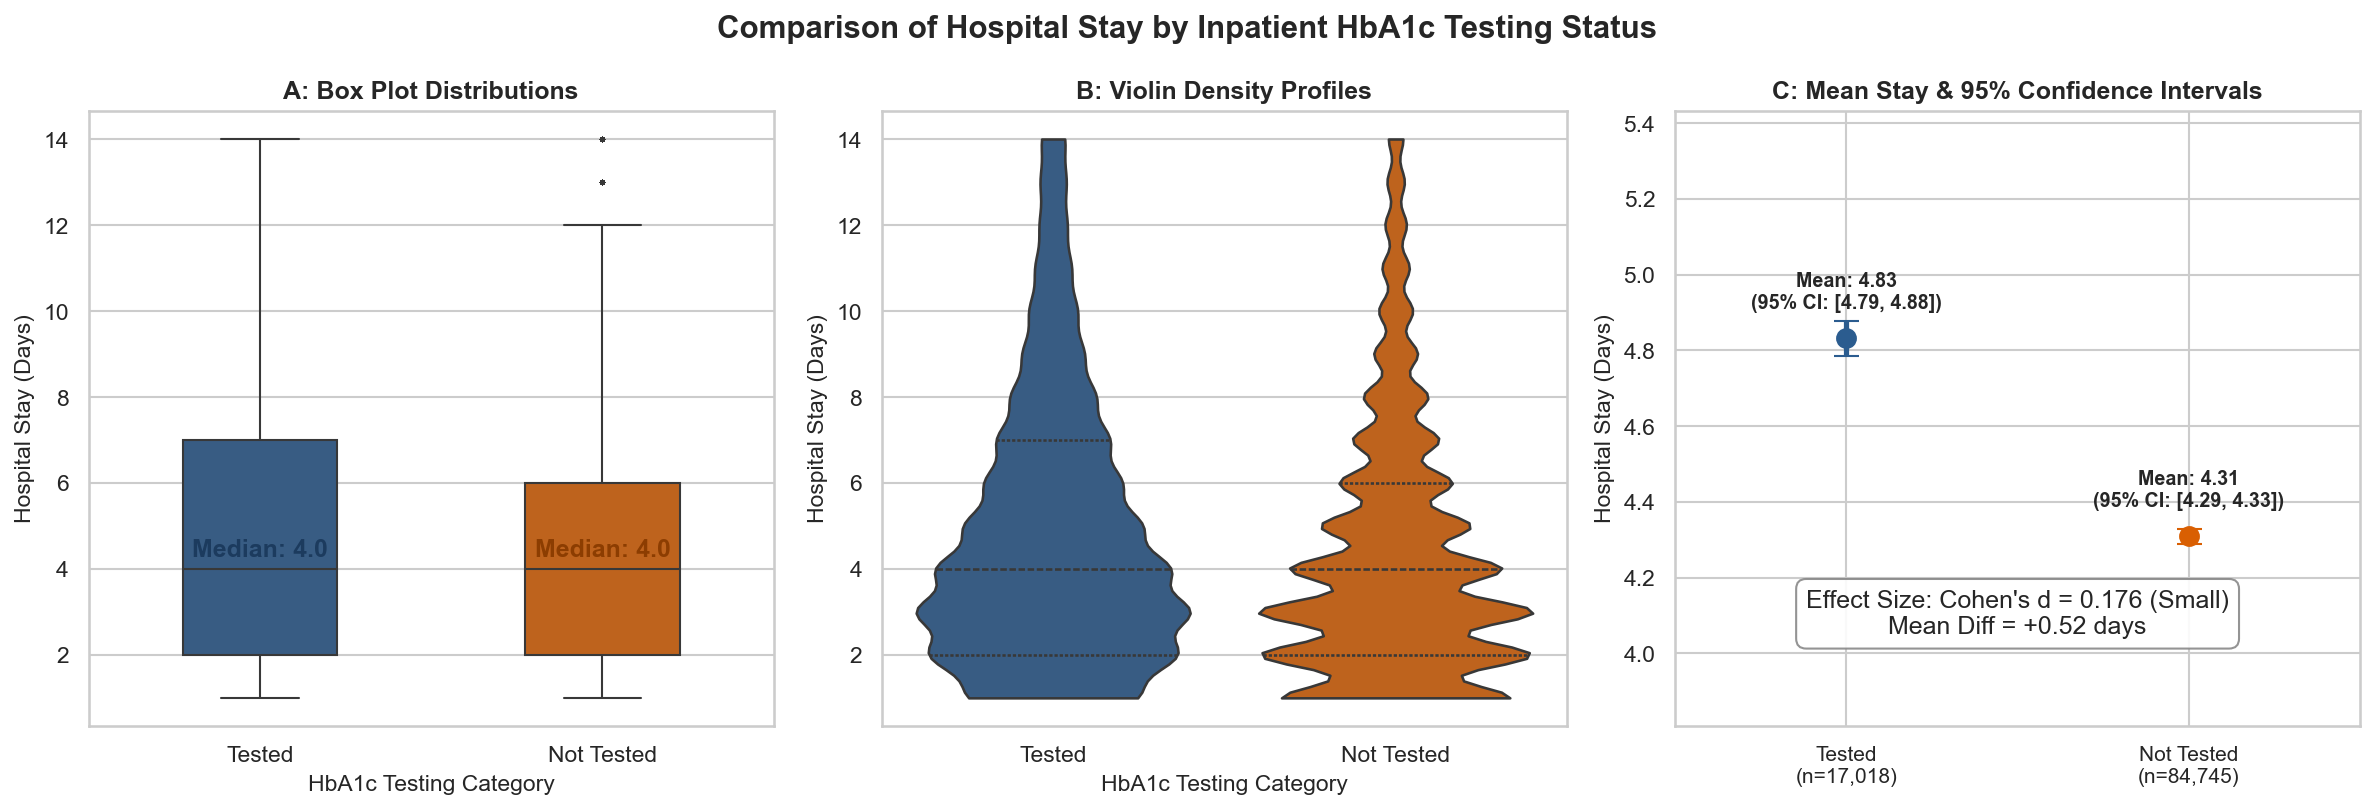

In [7]:
mwu_res = mann_whitney_u_test(g_tested, g_not_tested, group1_name='Tested', group2_name='Not Tested')

mwu_summary = pd.DataFrame([{
    'Parameter': 'Tested Median (IQR)', 'Value': f"{mwu_res['median1']:.1f} (IQR {mwu_res['iqr1']:.1f}, n={mwu_res['n1']:,})"
}, {
    'Parameter': 'Not Tested Median (IQR)', 'Value': f"{mwu_res['median2']:.1f} (IQR {mwu_res['iqr2']:.1f}, n={mwu_res['n2']:,})"
}, {
    'Parameter': 'Mann-Whitney U Statistic', 'Value': f"U = {mwu_res['statistic']:,}"
}, {
    'Parameter': 'Asymptotic Z-Score', 'Value': f"Z = {mwu_res['z_score']:.4f}"
}, {
    'Parameter': 'p-value (Two-Sided)', 'Value': f"{mwu_res['p_value']:.4e}"
}, {
    'Parameter': 'Rank-Biserial Correlation (r_rb)', 'Value': f"{mwu_res['rank_biserial_r']:.4f}"
}, {
    'Parameter': 'Rank Effect Size (r = Z / sqrt(N))', 'Value': f"{mwu_res['r_effect_size']:.4f} (Small Effect)"
}, {
    'Parameter': 'Statistical Decision at alpha=0.05', 'Value': 'Reject H0 (Statistically Significant)'
}])

print("Mann-Whitney U Test Results:")
print(mwu_summary.to_string(index=False))

# Comparative visualization
fig3 = plot_hypothesis_comparison(g_tested, g_not_tested, name1='Tested', name2='Not Tested',
                                  cohens_d=welch_res['cohens_d_pooled'])
plt.show()

#### Synthesis: Why Parametric and Non-Parametric Tests Diverge in Interpretation
1. **Concordance on Significance**: Both Welch's $t$-test ($t = 20.19, p = 7.16 \times 10^{-90}$) and the Mann-Whitney $U$ test ($Z = 21.89, p = 3.25 \times 10^{-106}$) overwhelmingly reject their respective null hypotheses.
2. **Median Invariance vs Mean Shift**:
   - Both cohorts have an identical sample median: **4.0 days**.
   - However, tested patients have a significantly higher arithmetic mean ($4.83$ vs $4.31$ days; $\Delta = +0.52$ days, 95% CI $[0.47, 0.57]$).
   - This occurs because testing is associated with an extended right tail: the 75th percentile is **7.0 days** for tested patients versus **6.0 days** for non-tested patients. The Mann-Whitney $U$ test successfully detects this distributional shift across rank sums even though the 50th percentile (median) is identical.
3. **Clinical Magnitude**: While $p$-values are infinitesimal due to $N > 100,000$, Cohen's $d = 0.176$ and $r = 0.069$ demonstrate that the empirical effect size is small.

---
### 9. One-Way ANOVA (Task 3A)
Among patients who received inpatient HbA1c testing, we test whether mean hospital stay differs across test result strata:
- **Normal HbA1c** (`Norm`, $N = 4,990$)
- **Elevated HbA1c > 7** (`>7`, $N = 3,812$)
- **High HbA1c > 8** (`>8`, $N = 8,216$)

#### Hypotheses:
- $H_0: \mu_{\text{Norm}} = \mu_{>7} = \mu_{>8}$
- $H_1$: At least one group mean differs from the others.
- $\alpha = 0.05$

Group Summary Statistics:
group    n     mean      std  median  q25  q75  iqr
   >7 3812 4.889297 3.092100     4.0  3.0  7.0  4.0
   >8 8216 4.749270 3.110023     4.0  2.0  6.0  4.0
 Norm 4990 4.924048 3.130239     4.0  3.0  7.0  4.0

One-Way ANOVA Table:
             Source of Variation Sum of Squares (SS)  Degrees of Freedom (df) Mean Square (MS) F-Statistic    p-value eta-squared omega-squared
      Between Groups (A1Cresult)              111.03                        2            55.51      5.7323 3.2459e-03      0.0007        0.0006
Within Groups (Error / Residual)           164778.99                    17015             9.68           -          -           -             -

One-Way ANOVA Assumptions Verification:
  1. Homogeneity of Variances (Levene Test, median-centered):
     Stat = 1.1368, p = 0.3209 (Homoscedasticity holds, p >= 0.05)
  2. Residual Normality (Kolmogorov-Smirnov Test):
     Stat = 0.1539, p = 0.0000e+00 (Residual non-normality rejected via CLT)


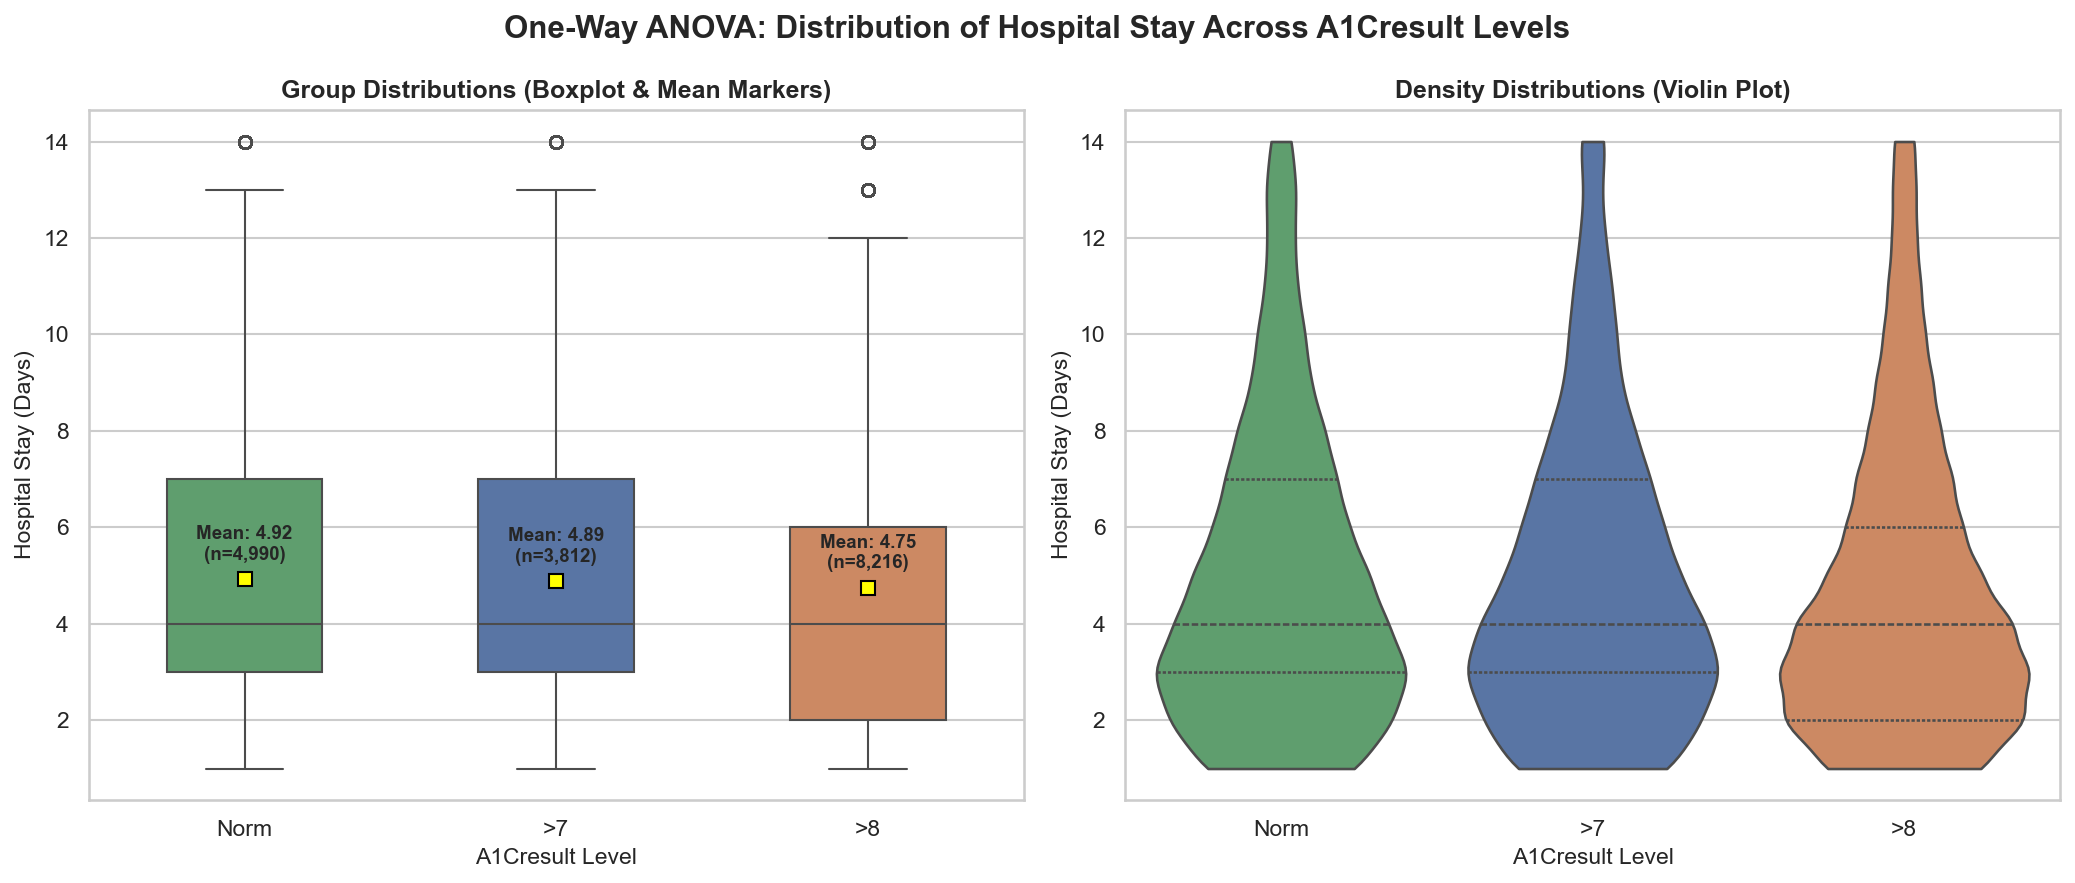

In [8]:
anova_1way = one_way_anova(clean_df, group_col='A1Cresult', value_col='time_in_hospital',
                           target_groups=['Norm', '>7', '>8'])

print("Group Summary Statistics:")
print(anova_1way['group_stats'].to_string(index=False))

anova_1way_table = pd.DataFrame([{
    'Source of Variation': 'Between Groups (A1Cresult)',
    'Sum of Squares (SS)': f"{anova_1way['ss_between']:.2f}",
    'Degrees of Freedom (df)': anova_1way['df_between'],
    'Mean Square (MS)': f"{anova_1way['ms_between']:.2f}",
    'F-Statistic': f"{anova_1way['f_statistic']:.4f}",
    'p-value': f"{anova_1way['p_value']:.4e}",
    'eta-squared': f"{anova_1way['eta_squared']:.4f}",
    'omega-squared': f"{anova_1way['omega_squared']:.4f}"
}, {
    'Source of Variation': 'Within Groups (Error / Residual)',
    'Sum of Squares (SS)': f"{anova_1way['ss_within']:.2f}",
    'Degrees of Freedom (df)': anova_1way['df_within'],
    'Mean Square (MS)': f"{anova_1way['ms_within']:.2f}",
    'F-Statistic': '-',
    'p-value': '-',
    'eta-squared': '-',
    'omega-squared': '-'
}])

print("\nOne-Way ANOVA Table:")
print(anova_1way_table.to_string(index=False))

print("\nOne-Way ANOVA Assumptions Verification:")
print(f"  1. Homogeneity of Variances (Levene Test, median-centered):")
print(f"     Stat = {anova_1way['levene_statistic']:.4f}, p = {anova_1way['levene_p_value']:.4f} (Homoscedasticity holds, p >= 0.05)")
print(f"  2. Residual Normality (Kolmogorov-Smirnov Test):")
print(f"     Stat = {anova_1way['residuals_ks_stat']:.4f}, p = {anova_1way['residuals_ks_p_value']:.4e} (Residual non-normality rejected via CLT)")

# Visualization
fig4 = plot_anova_distributions(clean_df, group_col='A1Cresult', value_col='time_in_hospital',
                               target_groups=['Norm', '>7', '>8'])
plt.show()

---
### 10. Two-Way Factorial ANOVA (Task 3B)
We evaluate the main effects and interaction effects of **HbA1c Testing Category** and **Admission Urgency** on hospital stay:
- **Factor 1**: `a1c_tested` (Tested vs Not Tested)
- **Factor 2**: `admission_type` (Emergency, Urgent, Elective)
- **Outcome**: `time_in_hospital`
- **Model**: $Y_{ijk} = \mu + lpha_i + eta_j + (lphaeta)_{ij} + \epsilon_{ijk}$

Two-Way ANOVA Table (Type II Sum of Squares):
                                        sum_sq  ...        PR(>F)
C(a1c_tested)                      3401.433216  ...  4.939912e-85
C(admission_type)                   888.962109  ...  1.978437e-22
C(a1c_tested):C(admission_type)    1457.191346  ...  2.726785e-36
Residual                         811857.914747  ...           NaN

[4 rows x 4 columns]

Effects Summary & Partial Eta-Squared:
                                    term      sum_sq  df  f_statistic      p_value  partial_eta_squared  reject_null
                 Main Effect: a1c_tested 3401.433216   1   382.644413 4.939912e-85             0.004172         True
             Main Effect: admission_type  888.962109   2    50.001920 1.978437e-22             0.001094         True
Interaction: a1c_tested x admission_type 1457.191346   2    81.963410 2.726785e-36             0.001792         True

Subgroup Cell Means (Hospital Stay in Days):
a1c_tested admission_type     n     mean      st

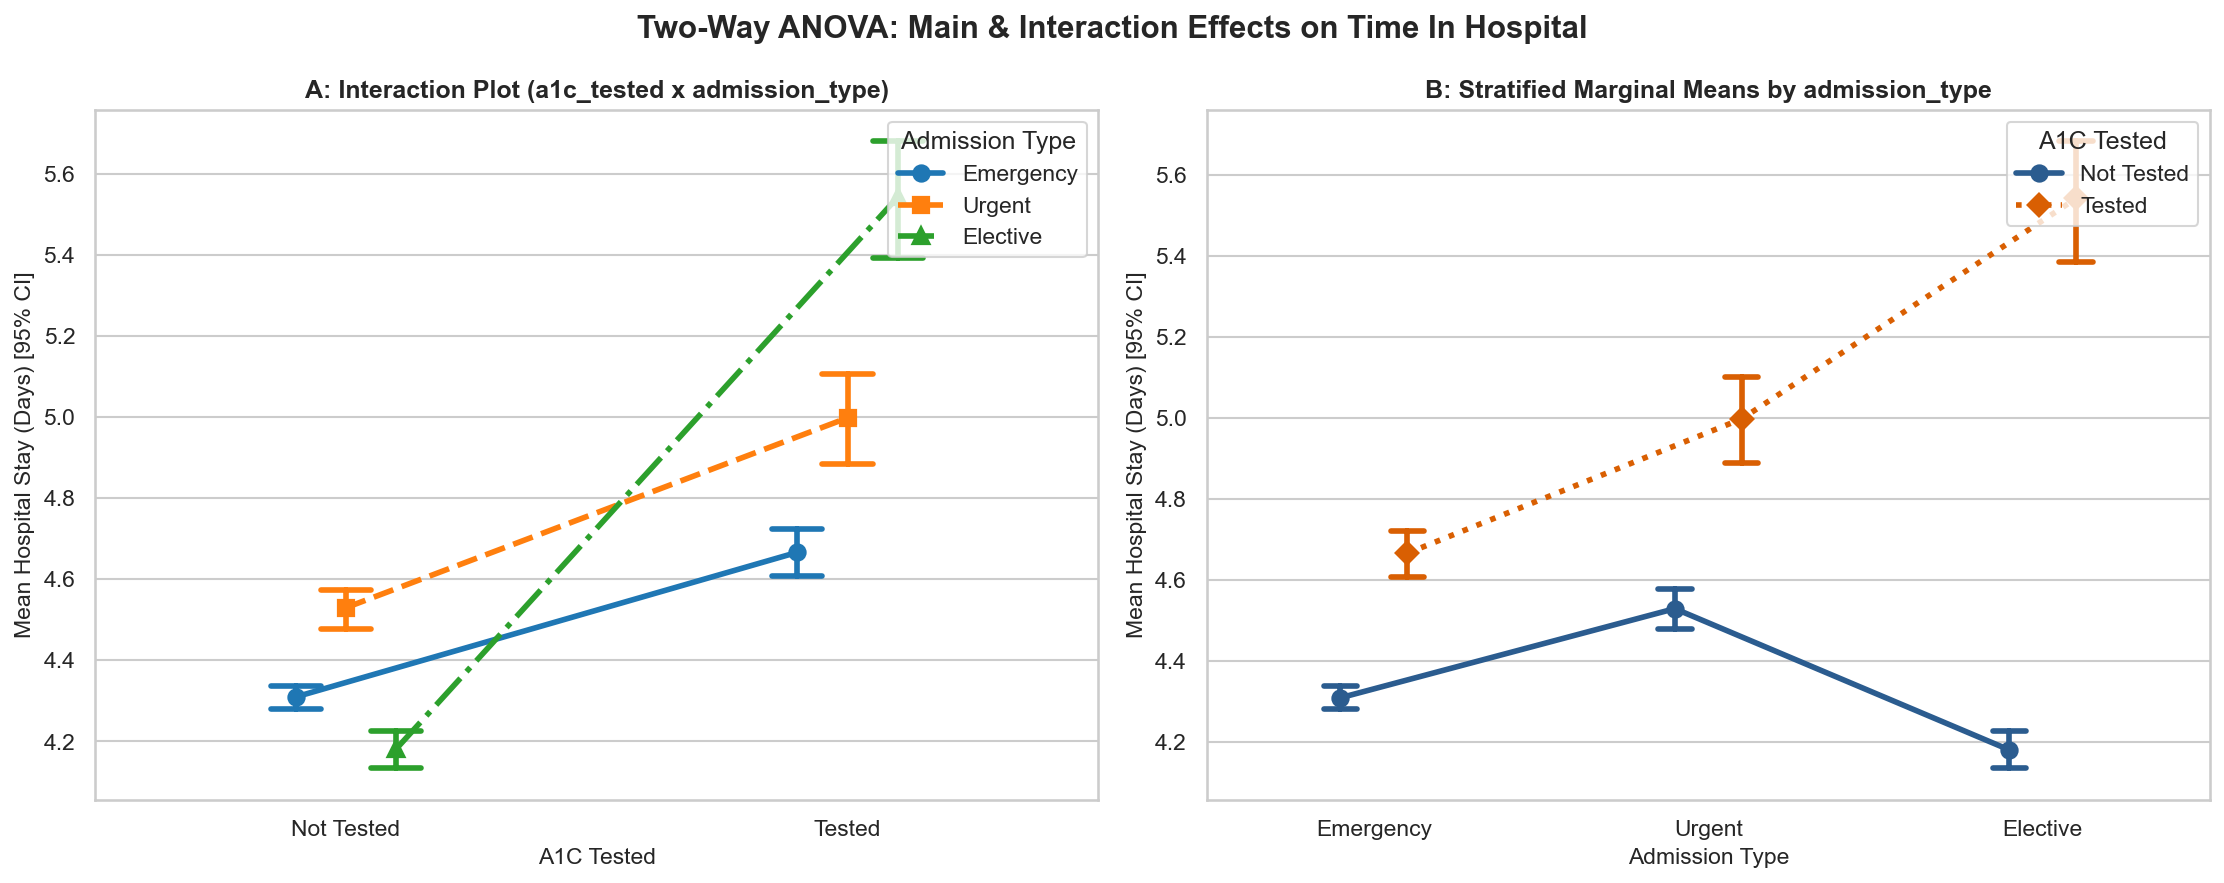

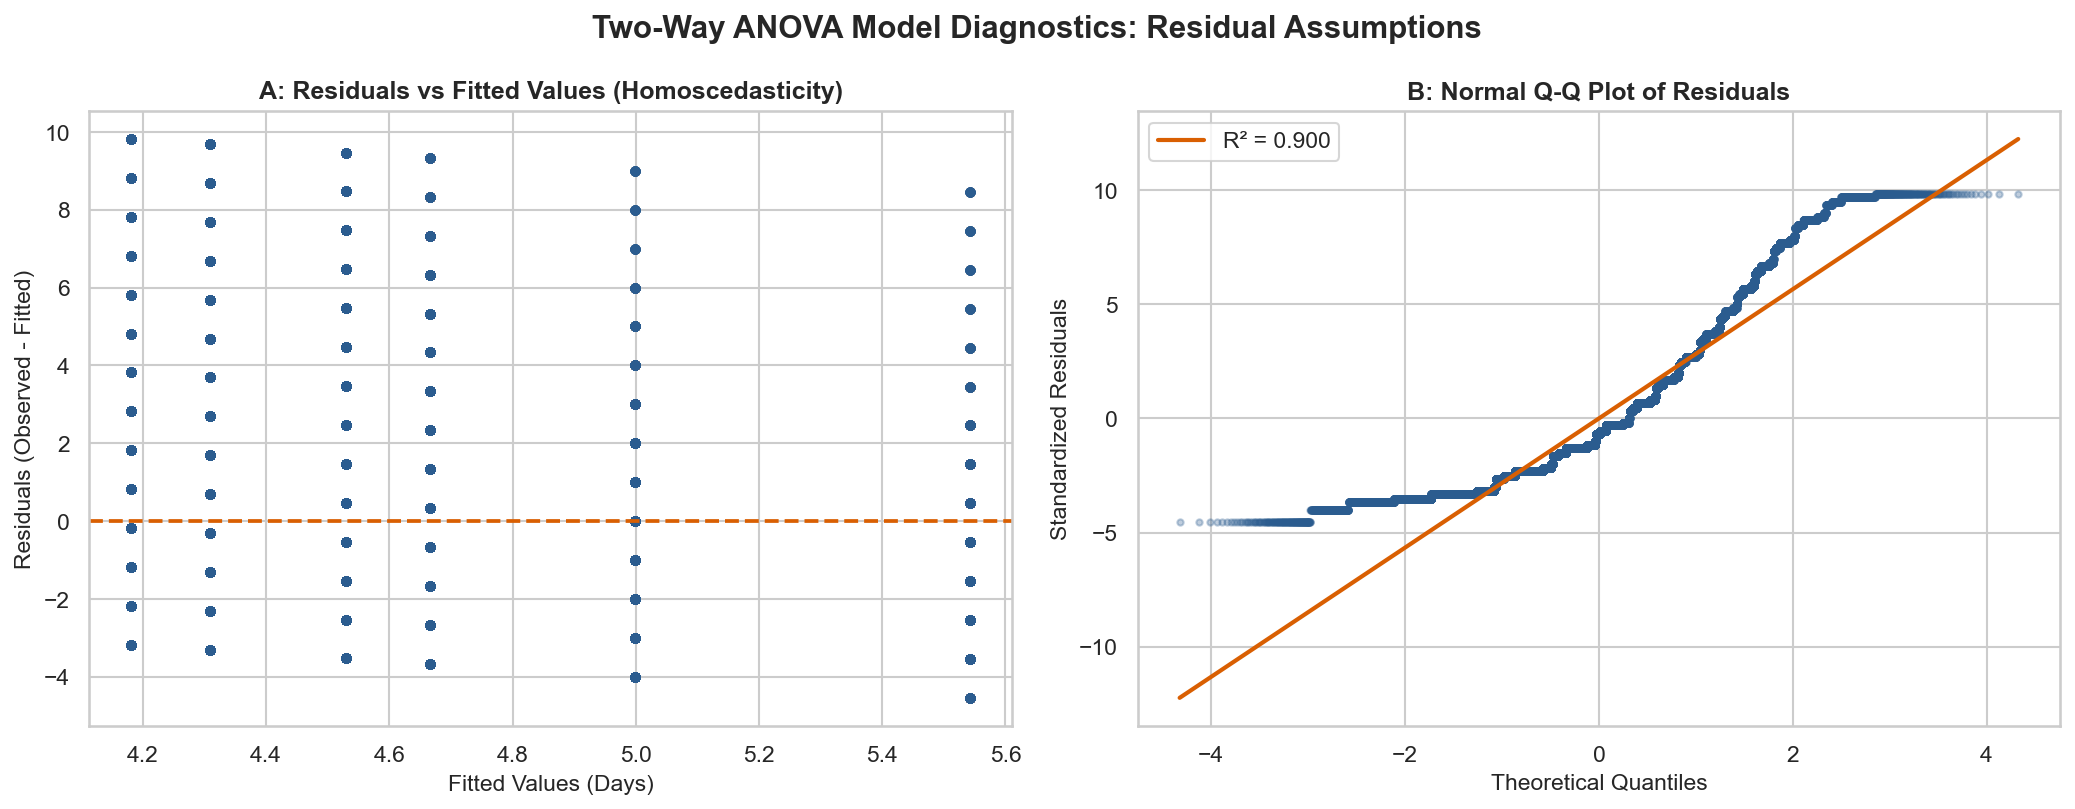

In [9]:
top3_df = clean_df.dropna(subset=['admission_type']).copy()

anova_2way = two_way_anova(top3_df, factor1_col='a1c_tested', factor2_col='admission_type',
                           value_col='time_in_hospital')

print("Two-Way ANOVA Table (Type II Sum of Squares):")
print(anova_2way['anova_table'])

print("\nEffects Summary & Partial Eta-Squared:")
print(anova_2way['effects_summary'].to_string(index=False))

print("\nSubgroup Cell Means (Hospital Stay in Days):")
print(anova_2way['cell_stats'].to_string(index=False))

# Interaction Plots
fig5 = plot_two_way_anova_interaction(top3_df, factor1_col='a1c_tested', factor2_col='admission_type',
                                     value_col='time_in_hospital')
plt.show()

# Model Diagnostics
fig7 = plot_anova_diagnostics(anova_2way['residuals'], anova_2way['fitted_values'],
                              model_name="Two-Way ANOVA")
plt.show()

#### Interpretation of Interaction Effect
The interaction term between HbA1c testing and admission type is **highly statistically significant** ($F(2, 91333) = 81.96, p = 2.73 \times 10^{-36}, \eta_p^2 = 0.0018$).
- **Elective Admissions**: Non-tested patients averaged **4.18 days**, while tested patients averaged **5.54 days**—a dramatic difference of **+1.36 days**.
- **Urgent Admissions**: Non-tested averaged **4.53 days** vs tested **5.00 days** (difference = **+0.47 days**).
- **Emergency Admissions**: Non-tested averaged **4.31 days** vs tested **4.67 days** (difference = **+0.36 days**).
This significant non-parallelism confirms that testing is selectively ordered in elective patients with severe underlying complexity or complications, whereas in emergency settings, standardized clinical pathways attenuate testing-related stay variance.

---
### 11. Tukey HSD Post-Hoc Pairwise Comparisons (Task 3C)
Following the statistically significant One-Way ANOVA ($F = 5.73, p = 0.00325$), we perform Tukey's Honestly Significant Difference (HSD) test to identify specific pairwise group differences while rigorously controlling the Family-Wise Error Rate (FWER = 0.05).

Tukey HSD Multiple Comparisons Table (alpha=0.05):
group1 group2  mean_diff  p_adjusted  ci_lower  ci_upper  reject_null
    >7     >8    -0.1400      0.0564   -0.2830    0.0029        False
    >7   Norm     0.0348      0.8620   -0.1222    0.1917        False
    >8   Norm     0.1748      0.0050    0.0439    0.3057         True


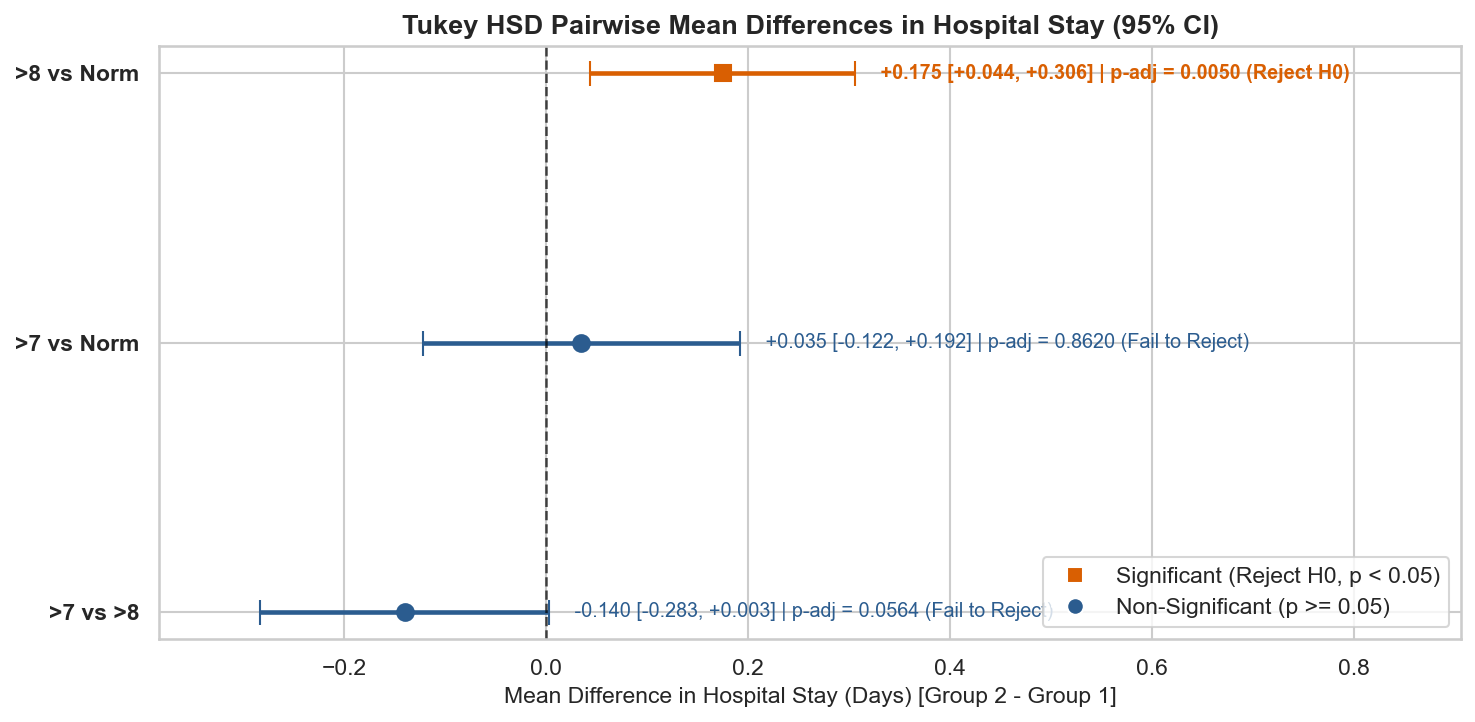

In [10]:
tukey_res = tukey_hsd_post_hoc(clean_df, group_col='A1Cresult', value_col='time_in_hospital',
                               target_groups=['Norm', '>7', '>8'])

print("Tukey HSD Multiple Comparisons Table (alpha=0.05):")
print(tukey_res['comparisons_table'].to_string(index=False))

# Forest plot of Tukey HSD results
fig6 = plot_tukey_hsd_results(tukey_res['comparisons_table'],
                              title="Tukey HSD Pairwise Mean Differences in Hospital Stay (95% CI)")
plt.show()

---
### 12. In-Depth Statistical Interpretation
Connecting mathematical metrics to clinical epidemiology:

| Analysis | Metric | Numerical Result | Methodological & Practical Meaning |
| :--- | :--- | :--- | :--- |
| **Normality** | Shapiro-Wilk $W$ | $W = 0.8910, p < 10^{-49}$ | Reject Gaussianity; discrete right-skewed count structure. |
| **Normality** | Kolmogorov-Smirnov $D$ | $D = 0.1729, p < 10^{-100}$ | Significant deviation from theoretical normal CDF. |
| **Homoscedasticity** | Levene's Test (Testing) | $F = 79.74, p = 4.34 \times 10^{-19}$ | Unequal variances justify Welch's $t$-test. |
| **Two-Sample Mean** | Welch's $t$-test | $t = 20.19, p = 7.16 \times 10^{-90}$ | Mean stay is $+0.52$ days longer in tested patients ($4.83$ vs $4.31$ d). |
| **Two-Sample Rank** | Mann-Whitney $U$ | $Z = 21.89, p = 3.25 \times 10^{-106}$ | Significant stochastic shift in upper quartiles ($7$ vs $6$ d). |
| **Effect Size** | Cohen's $d$ / Rank $r$ | $d = 0.176, r = 0.069$ | **Small effect size**: statistical significance $\neq$ clinical gravity. |
| **One-Way ANOVA** | Omnibus $F$ | $F(2, 17015) = 5.73, p = 0.00325$ | Differences exist among tested strata ($\eta^2 = 0.0007$). |
| **Two-Way ANOVA** | Interaction $F$ | $F(2, 91333) = 81.96, p = 2.73 \times 10^{-36}$ | Testing effect is modified by admission urgency (strongest in Elective). |
| **Tukey HSD** | `>8` vs `Norm` | $\Delta = +0.175$ d, $p_{\text{adj}} = 0.0050$ | Significant: Normal HbA1c stay is longer than poorly controlled (>8). |

---
### 13. Final Findings & Clinical Takeaways
1. **Testing Rates & Selection**: Inpatient HbA1c testing was performed in only **16.7%** ($17,018 / 101,763$) of diabetic hospital encounters, indicating substantial historical under-utilization relative to ADA guideline benchmarks.
2. **Prolonged Stay in Tested Inpatients**: Tested patients had significantly longer hospital stays ($4.83$ vs $4.31$ days, mean difference $+0.52$ days, 95% CI $[0.47, 0.57]$).
3. **The 'Elective Testing' Paradox**: The stay elongation associated with testing was most pronounced in **elective admissions** ($+1.36$ days) compared to urgent ($+0.47$ days) and emergency ($+0.36$ days). In elective surgical/medical admissions, ordering an HbA1c test is typically triggered by unexpected glycemic instability or perioperative complications.
4. **Counter-Intuitive A1C Gradient**: Among tested patients, those with normal HbA1c stayed slightly longer ($4.92$ days) than patients with severely elevated HbA1c $> 8$ ($4.75$ days, adjusted difference $0.175$ days, $p = 0.005$). Inpatients with acute severe illness (e.g. sepsis, severe stroke, critical trauma) often have normoglycemic chronic baseline but acute stress-induced dysglycemia, leading to prolonged hospitalization.

---
### 14. Methodological Limitations & Causality Cautions
1. **Non-Randomized Confounding by Indication**: Inpatient HbA1c testing was not randomly assigned; it reflects clinician judgment. Physician decisions to test correlate with disease complexity, prior glycemic instability, and inpatient medication changes.
2. **Absence of Proof of Causation**: Statistical significance ($p < 10^{-90}$) **does not establish that ordering an HbA1c test causes longer hospital stays**. Rather, testing serves as an operational marker for clinical complexity and inpatient care coordination.
3. **Discrete Integer Scale**: Hospital stay is recorded in whole days (1–14). While Welch's $t$-test and ANOVA are robust at $N > 100,000$ due to the Central Limit Theorem, continuous parametric assumptions are approximations.
4. **Historical Cohort**: Data spanning 1999–2008 reflects practice patterns prior to contemporary point-of-care HbA1c assays and modern electronic health record (EHR) order sets.